In [ ]:
import pandas as pd

data = {'job_title_short': ['Data Scientist', 'Software Engineer', 'Data Analyst'],
        'job_skills': [['excel', 'sql', 'python'], ['java', 'c++', 'git'], ['excel', 'sql', 'tableau']]
}


df_skills_lists = pd.DataFrame(data)

df_skills_lists

,job_title_short,job_skills
0,Data Scientist,"[excel, sql, python]"
1,Software Engineer,"[java, c++, git]"
2,Data Analyst,"[excel, sql, tableau]"


<Axes: xlabel='job_skills'>

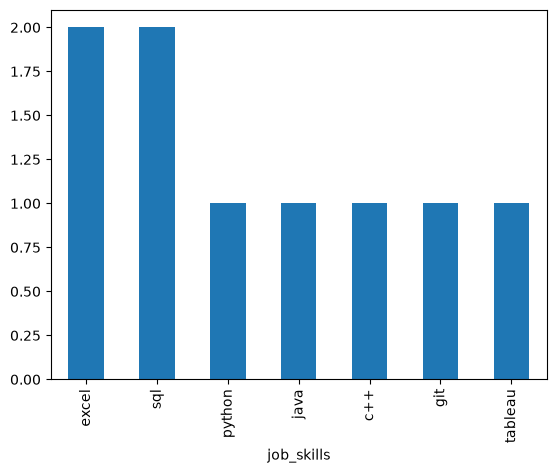

In [ ]:
df_skills_lists.explode('job_skills').value_counts('job_skills').plot(kind= 'bar')

In [ ]:
import pandas as pd
from datasets import load_dataset
import matplotlib.pyplot as plt

dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])

In [ ]:
import ast
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

In [ ]:
df_exploaded = df.explode('job_skills')

<Axes: xlabel='job_skills'>

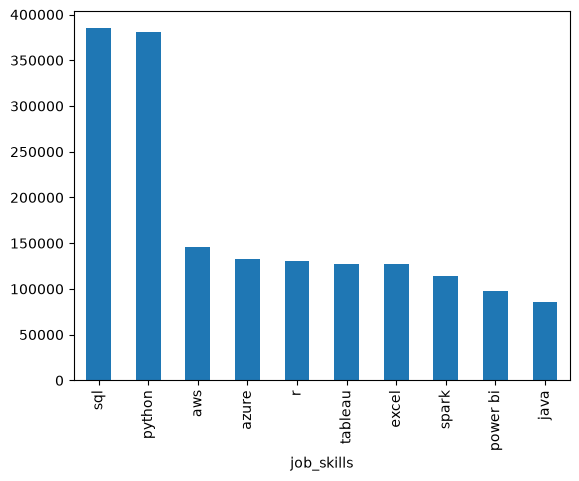

In [ ]:
df_exploaded['job_skills'].value_counts().head(10).plot(kind='bar')

In [ ]:
skills_counts = df_exploaded.groupby(['job_title_short', 'job_skills']).size()

type(skills_counts)

pandas.Series

In [ ]:
df_skills_count = skills_counts.reset_index(name='skill_count')

df_skills_count = df_skills_count.sort_values(by='skill_count', ascending=False)

df_skills_count

,job_title_short,job_skills,skill_count
1066,Data Scientist,python,113711
865,Data Engineer,sql,113130
830,Data Engineer,python,108022
625,Data Analyst,sql,92428
1101,Data Scientist,sql,78982
...,...,...,...
462,Data Analyst,chainer,1
432,Cloud Engineer,wrike,1
410,Cloud Engineer,theano,1
24,Business Analyst,chainer,1


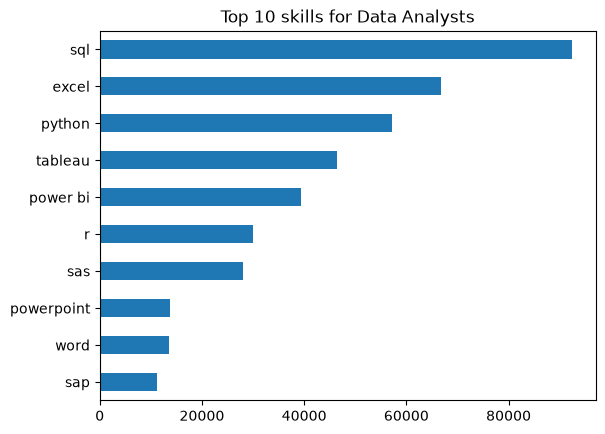

In [ ]:
job_title = 'Data Analyst'
top_skills = 10

df_skill_final = df_skills_count[df_skills_count['job_title_short'] == job_title].head(top_skills)

df_skill_final.plot(kind='barh', x='job_skills', y='skill_count')
plt.gca().invert_yaxis()
plt.title(f'Top {top_skills} skills for {job_title}s')
plt.ylabel('')
plt.legend().set_visible(False)